## Lab 6: Missing Data, Regularization, Logistic Regression
### Fiona St. Clair

AI Disclosure: Claude Sonnet AI was used to help adapt the code from the instructions, class slideshows, and class notebooks into this lab. The written responses are my own logical and reasoning. 

***

### **Part 1: Missing Data and Imputation**

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
framingham = pd.read_csv("../../../data/framingham.csv")
print(framingham.isna().sum())
print("-----------------------")
print(framingham.shape)

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64
-----------------------
(4240, 16)


In [3]:
predictors = ['age', 'cigsPerDay', 'sysBP', 'BMI']
framingham_cc = framingham[predictors + ['totChol']]

X = framingham_cc[predictors]
y = framingham_cc['totChol']

try:
    model1_sk = LinearRegression().fit(X, y)
except ValueError as e:
    print("ValueError:", e)

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values


**1A:** The cell errors because sklearn's LinearRegression can't handle missing values. In this cell we didn't drop or fill in the NaNs in cigsPerDay and BMI, so the fit fails. We have to drop the rows or impute them first.

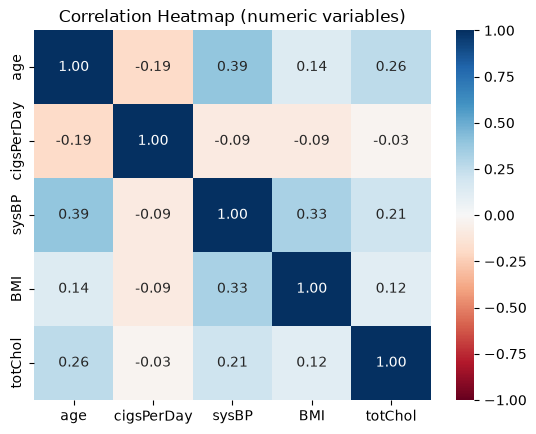

In [4]:
num_cols = ['age', 'cigsPerDay', 'sysBP', 'BMI', 'totChol']
corr = framingham[num_cols].corr()

sns.heatmap(
    corr, annot=True, fmt=".2f",
    cmap="RdBu", vmin=-1, vmax=1
)
plt.title("Correlation Heatmap (numeric variables)")
plt.show()

**1B:** The correlations are all pretty weak. totChol is most related to age (0.26) and sysBP (0.21), and almost not at all to cigsPerDay (-0.03). This tells us the predictors don't explain much of totChol, so we should expect a low R-squared. sysBP is also related to age (0.39) and BMI (0.33), so we could use those to predict sysBP when it is missing.

In [5]:
missing_framingham = framingham.copy()
missing_framingham.loc[missing_framingham.sample(frac=0.8, random_state=567).index, 'sysBP'] = np.nan

model1 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=framingham).fit()
model2 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=missing_framingham).fit()

print(f"Number of observations used in model 1: {model1.nobs}")
print(f"Number of observations used in model 2: {model2.nobs}")

Number of observations used in model 1: 4143.0
Number of observations used in model 2: 829.0


**1C:** This is MCAR (missing completely at random). We picked 80% of the rows at random to delete, so every row had the same chance of losing its sysBP value. It didn't depend on the sysBP value itself or on any other variable.

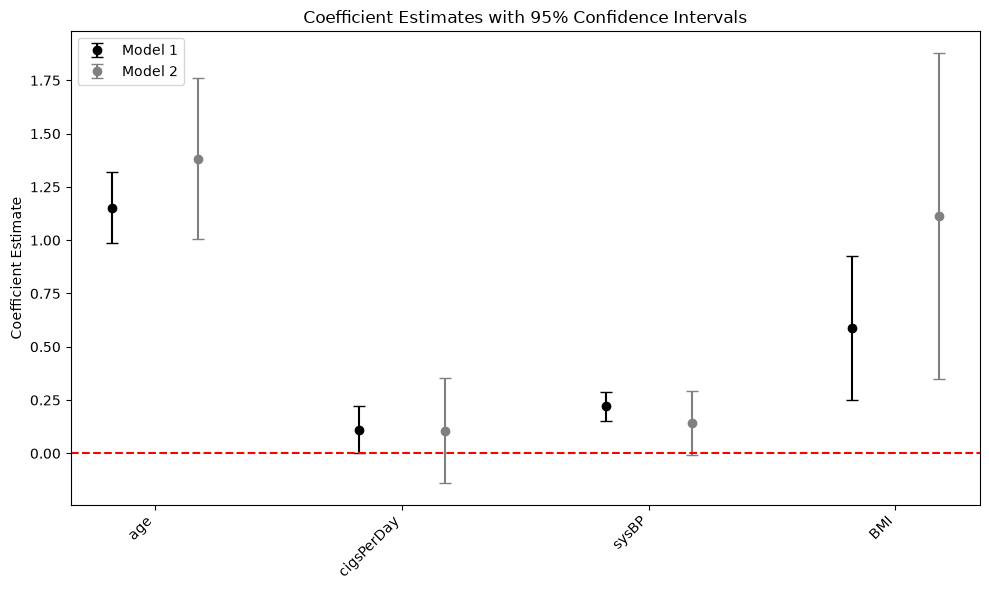

Model 1               Model 2              
             lower  upper   coef   lower  upper   coef
age          0.985  1.320  1.152   1.006  1.760  1.383
cigsPerDay   0.000  0.223  0.112  -0.140  0.351  0.106
sysBP        0.153  0.288  0.221  -0.010  0.294  0.142
BMI          0.251  0.926  0.589   0.349  1.879  1.114

In [6]:
def coef_table(model):
    """Coefficients and 95% CIs, without the intercept."""
    table = model.conf_int().drop("Intercept")
    table.columns = ["lower", "upper"]
    table["coef"] = model.params.drop("Intercept")
    return table

models = {"Model 1": (model1, "black"), "Model 2": (model2, "gray")}
tables = {name: coef_table(m) for name, (m, _) in models.items()}
common_vars = tables["Model 1"].index.intersection(tables["Model 2"].index)

x = np.arange(len(common_vars))
width = 0.35

plt.figure(figsize=(10, 6))
for offset, (name, (_, color)) in zip([-width/2, width/2], models.items()):
    t = tables[name].loc[common_vars]
    plt.errorbar(
        x + offset, t["coef"],
        yerr=[t["coef"] - t["lower"], t["upper"] - t["coef"]],
        fmt='o', color=color, ecolor=color, capsize=4, label=name
    )

plt.axhline(0, color='red', linestyle='--')
plt.xticks(x, common_vars, rotation=45, ha='right')
plt.ylabel('Coefficient Estimate')
plt.title('Coefficient Estimates with 95% Confidence Intervals')
plt.legend()
plt.tight_layout()
plt.show()

pd.concat([tables["Model 1"], tables["Model 2"]], axis=1, keys=["Model 1", "Model 2"]).round(3)

**1D:** The coefficients in Model 2 are close to Model 1, so removing the data at random didn't really bias the estimates. What changed is that the confidence intervals are much wider, since we only have about 800 rows instead of about 4100. The biggest effect is on sysBP...in Model 1 the interval doesn't include 0 (0.15 to 0.29), but in Model 2 it does (-0.01 to 0.29). So with less data we are less sure that sysBP matters.

In [7]:
mean_framingham = missing_framingham.copy()

mean_sysBP = mean_framingham['sysBP'].mean(skipna=True)
mean_framingham['sysBP'] = mean_framingham['sysBP'].fillna(mean_sysBP)

print("Mean sysBP (20% observed):", round(mean_sysBP, 2))
print("Mean sysBP (full data):   ", round(framingham['sysBP'].mean(), 2))

Mean sysBP (20% observed): 133.95
Mean sysBP (full data):    132.35


**1E:** In a real situation we would only have the data we observed, so the mean of the remaining 20% is the only mean we could calculate. Using the mean of the full dataset would use the values that we are pretending are missing, which is not realistic. In this case the two means are close (133.95 vs 132.35) because the data was deleted at random.

***

### **Part 2: Regularization**

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression, RidgeCV, lasso_path
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

auto = pd.read_csv("../../../data/Auto.csv", na_values="?").dropna().reset_index(drop=True)

num = ["displacement", "horsepower", "weight", "acceleration", "year"]
X = auto[num]
y = auto["mpg"]

SEED = 200
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

alphas = np.logspace(-3, 3, 100)
auto.shape

(392, 9)

In [9]:
ols_all = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)

three = ["horsepower", "weight", "year"]
ols_three = make_pipeline(StandardScaler(), LinearRegression()).fit(X[three], y)

coef_df = pd.DataFrame(index=num)
coef_df["OLS (all 5)"] = ols_all[-1].coef_
coef_df["OLS (3 features)"] = pd.Series(ols_three[-1].coef_, index=three)
coef_df.round(3)

,OLS (all 5),OLS (3 features)
displacement,0.291,NaN
horsepower,0.039,-0.192
weight,-5.831,-5.470
acceleration,0.249,NaN
year,2.774,2.755


**1B:** For OLS, changing the scale of a variable just changes its coefficient, so the predictions stay the same. Ridge and lasso put a penalty on the size of the coefficients. If the variables are on different scales (weight is in the thousands, acceleration is around 15) then the penalty hits them unevenly just because of their units. Standardizing puts everything on the same scale so the penalty is fair.

In [10]:
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=cv)).fit(X, y)

print("Ridge alpha_:", round(ridge[-1].alpha_, 4))

coef_df["Ridge"] = ridge[-1].coef_
coef_df.round(3)

Ridge alpha_: 1.2328


,OLS (all 5),OLS (3 features),Ridge
displacement,0.291,NaN,0.147
horsepower,0.039,-0.192,-0.044
weight,-5.831,-5.470,-5.634
acceleration,0.249,NaN,0.201
year,2.774,2.755,2.753


In [11]:
print("Number of exactly-zero ridge coefficients:", (coef_df["Ridge"] == 0).sum())
print()
print("Change from full OLS to Ridge:")
print((coef_df["Ridge"] - coef_df["OLS (all 5)"]).round(3))

Number of exactly-zero ridge coefficients: 0

Change from full OLS to Ridge:
displacement   -0.143
horsepower     -0.084
weight          0.197
acceleration   -0.048
year           -0.022
dtype: float64


**2B/2C:** The ridge penalty chosen was alpha = 1.23. None of the ridge coefficients are exactly zero, since ridge shrinks them but doesn't remove them. Compared to OLS, weight changed the most (-5.83 to -5.63), then displacement (0.29 to 0.15) and horsepower (0.04 to -0.04). Year barely changed (2.77 to 2.75). The ones that changed are the ones that are collinear with each other.

In [12]:
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=cv)).fit(X, y)

print("Lasso alpha_:", round(lasso[-1].alpha_, 4))

coef_df["Lasso"] = lasso[-1].coef_
coef_df.round(3)

Lasso alpha_: 0.0498


,OLS (all 5),OLS (3 features),Ridge,Lasso
displacement,0.291,NaN,0.147,-0.000
horsepower,0.039,-0.192,-0.044,-0.000
weight,-5.831,-5.470,-5.634,-5.532
acceleration,0.249,NaN,0.201,0.154
year,2.774,2.755,2.753,2.721


In [13]:
print("Dropped by lasso:", list(coef_df.index[coef_df["Lasso"] == 0]))

Dropped by lasso: ['displacement', 'horsepower']


**3B:** The lasso penalty chosen was alpha = 0.05. Lasso dropped displacement and horsepower (their coefficients went to zero) and kept weight, year, and acceleration.

**3C:** Forward/backward selection adds or drops one variable at a time and never goes back, so it can get stuck with a bad choice, especially with collinear variables. Lasso looks at all the variables together, and the penalty is picked using cross-validation, so we can trust it more. Some limits are that lasso tends to pick just one of a group of correlated variables, so a dropped variable may still be useful. The coefficients are also shrunk toward zero, and we don't get to pick how many features it keeps.

In [14]:
enet = make_pipeline(
    StandardScaler(),
    ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.5, 0.9, 1], cv=cv)
).fit(X, y)

print("ElasticNet alpha_:   ", round(enet[-1].alpha_, 4))
print("ElasticNet l1_ratio_:", enet[-1].l1_ratio_)

coef_df["ElasticNet"] = enet[-1].coef_
coef_df.round(3)

ElasticNet alpha_:    0.0498
ElasticNet l1_ratio_: 1.0


,OLS (all 5),OLS (3 features),Ridge,Lasso,ElasticNet
displacement,0.291,NaN,0.147,-0.000,-0.000
horsepower,0.039,-0.192,-0.044,-0.000,-0.000
weight,-5.831,-5.470,-5.634,-5.532,-5.532
acceleration,0.249,NaN,0.201,0.154,0.154
year,2.774,2.755,2.753,2.721,2.721


**4B:** The chosen alpha was 0.05 and the chosen l1_ratio was 1.0. An l1_ratio of 1 means it is a pure lasso, so cross-validation decided adding any ridge penalty didn't help. That is why the ElasticNet coefficients are the same as the lasso ones.

**4C:** All of the methods agree that weight (negative, by far the largest) and year (positive) are the most important. Lasso and ElasticNet also keep acceleration with a small coefficient. Displacement and horsepower are the least important: they are dropped by lasso and ElasticNet and are small in ridge.

***

### **Part 3: Logistic Regression**

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

fram = pd.read_csv("../../../data/framingham.csv").dropna()
y = fram["TenYearCHD"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_model(numeric):
    preprocess = ColumnTransformer(transformers=[
        ("binary", "passthrough", ["male"]),
        ("numeric", StandardScaler(), [numeric]),
    ])
    return Pipeline(steps=[("preprocess", preprocess), ("model", LogisticRegression())])

X_A = fram[["male", "age"]]
X_B = fram[["male", "cigsPerDay"]]
pipe_A = make_model("age")
pipe_B = make_model("cigsPerDay")
fram.shape

(3658, 16)

In [16]:
# a. fraction of patients who developed CHD
base_rate = y.mean()
print(f"Fraction with CHD:          {base_rate:.4f}")

# b. accuracy of predicting "no CHD" for everyone
acc_base = accuracy_score(y, np.zeros(len(y)))
print(f"Accuracy of all-zero model: {acc_base:.4f}")

# c. log loss when every patient gets p = base rate
ll_base = log_loss(y, np.full(len(y), base_rate))
print(f"Base log loss:              {ll_base:.4f}")

Fraction with CHD:          0.1523
Accuracy of all-zero model: 0.8477
Base log loss:              0.4266


**1A:** About 15.2% of patients developed CHD within 10 years.

**1B:** Predicting no CHD for everyone gives an accuracy of about 84.8%.

**1C:** The log loss for this model is 0.4266.

In [17]:
pipe_A.fit(X_A, y)
pipe_B.fit(X_B, y)

p_A = pipe_A.predict_proba(X_A)[:, 1]
p_B = pipe_B.predict_proba(X_B)[:, 1]

ll_A = log_loss(y, p_A)
ll_B = log_loss(y, p_B)
print(f"Model A log loss (sklearn): {ll_A:.4f}")
print(f"Model B log loss (sklearn): {ll_B:.4f}")

Model A log loss (sklearn): 0.3942
Model B log loss (sklearn): 0.4222


In [18]:
ll_A_hand = -np.mean(y * np.log(p_A) + (1 - y) * np.log(1 - p_A))
print(f"Model A log loss (by hand): {ll_A_hand:.4f}")
print(np.isclose(ll_A, ll_A_hand))

Model A log loss (by hand): 0.3942
True


**2B:** The log loss for Model A is 0.3942 and for Model B is 0.4222. Both are lower than the baseline of 0.4266, but Model B is only a tiny bit lower.

**2C:** The log loss by hand for Model A is 0.3942, which matches sklearn.

In [19]:
scoring = ["accuracy", "neg_log_loss", "roc_auc"]

rows = {}
for name, pipe, X_ in [("Model A (male + age)", pipe_A, X_A), ("Model B (male + cigsPerDay)", pipe_B, X_B)]:
    res = cross_validate(pipe, X_, y, cv=cv, scoring=scoring)
    rows[name] = {
        "accuracy mean": res["test_accuracy"].mean(),
        "accuracy std": res["test_accuracy"].std(),
        "log loss mean": -res["test_neg_log_loss"].mean(),   # flip the sign back
        "log loss std": res["test_neg_log_loss"].std(),
        "roc_auc mean": res["test_roc_auc"].mean(),
        "roc_auc std": res["test_roc_auc"].std(),
    }

cv_table = pd.DataFrame(rows).T
print(f"Baseline accuracy: {acc_base:.4f}  |  Baseline log loss: {ll_base:.4f}")
cv_table.round(4)

Baseline accuracy: 0.8477  |  Baseline log loss: 0.4266


,accuracy mean,accuracy std,log loss mean,log loss std,roc_auc mean,roc_auc std
Model A (male + age),0.8480,0.0010,0.3953,0.0134,0.7013,0.0396
Model B (male + cigsPerDay),0.8477,0.0006,0.4233,0.0023,0.5645,0.0319


**3A/3B:** The results are in the table above. Both models have a CV accuracy of about 0.848, which is the same as the baseline accuracy of 0.8477. So accuracy is not useful for choosing between them, because only about 15% of patients have CHD and just predicting no for everyone already gets a high accuracy. Log loss and AUC show a clearer difference. Model A has a log loss of 0.395 and an AUC of 0.70, while Model B has a log loss of 0.423 and an AUC of 0.56 (0.5 would be random guessing).

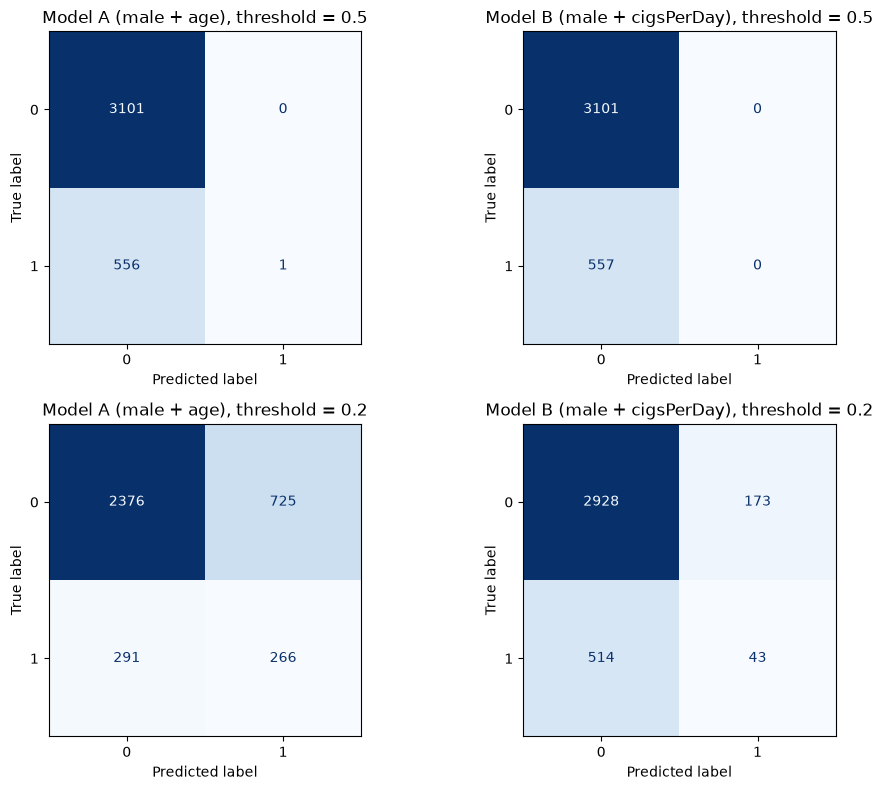

In [20]:
p_cv_A = cross_val_predict(pipe_A, X_A, y, cv=cv, method="predict_proba")[:, 1]
p_cv_B = cross_val_predict(pipe_B, X_B, y, cv=cv, method="predict_proba")[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, threshold in zip(axes, [0.5, 0.2]):
    for ax, p, title in zip(row, [p_cv_A, p_cv_B], ["Model A (male + age)", "Model B (male + cigsPerDay)"]):
        y_hat = (p >= threshold).astype(int)
        ConfusionMatrixDisplay.from_predictions(y, y_hat, ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{title}, threshold = {threshold}")

plt.tight_layout()
plt.show()

**3C:** At a threshold of 0.5, neither model is useful. Model A predicts CHD for only 1 patient and Model B never predicts it, so both miss almost all of the 557 CHD patients. At 0.2, Model A catches 266 of the 557 CHD patients but has 725 false positives. Model B only catches 43 with 173 false positives. Lowering the threshold trades false negatives for false positives, and Model A gives us a much better trade.

**3D:** I would choose Model A. It has the lower log loss (0.395 vs 0.423), the higher AUC (0.70 vs 0.56), and it catches many more CHD patients at the 0.2 threshold. Model B's log loss is barely lower than the baseline of 0.4266, which means male and cigsPerDay don't tell us much more than just knowing the overall CHD rate. Model A is clearly better than the baseline, so age adds real information.